---
This is some fairly in depth fitting of all the reflectivity data from nEXO

Fits the data MANY different ways (nuisance parameters)
The bottom show the possible evidence for the vertical fill factor

All results give thickness between 16 and 18 nm

It uses the fitting tools written explicitly in here.

Importing and calling ...../Fitting/GenPaths.py
added to path: ['/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/Fitting', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling']
PROPATH variable: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


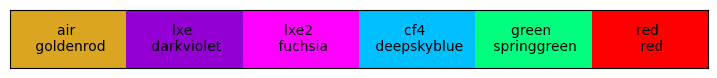

In [1]:
from GenPaths import * # this provides PROPATH which can help load stuff (and the paths to find the PDEhelpers stuff)

# from lmfit import Model, Parameters
# import lmfit as lm
import inspect

from scipy import optimize as opt
from scipy.signal import find_peaks


# if you want this to be easier
#export PYTHONPATH="${PYTHONPATH}:/full/path/to/helpers"

import numpy as np
import matplotlib.pyplot as plt

# from PDEhelpers import * # this causes errors because of class naming same as module naming
from PDEhelpers.PhotonInfo import *
from PDEhelpers.OpticsDataLoader import *

from scipy.ndimage import gaussian_filter1d, uniform_filter
from scipy.optimize import curve_fit

from PDEhelpers import PDEStyle as MS
MS.ShowMyStyles()
ms = MS.MyStyleSet()
ms.SetMPLcolors()

In [2]:
## Doing single nuisance parameter scale down (sd1 = sd2)

def func_Ref(wlen, theta1 = 0, toxide=16.5, FF=0.7, scaleDown=0.3, gausSigma=None, dh=None):
    photon = PhotonInfo(wlen, theta_1=theta1, dataHelper=dh)
    totalRef = FF * (1-scaleDown) * photon.Wave_TotalReflection(toxide)
    
    # print("theta1", theta1, "toxide", toxide, "FF", FF, "scaleDown", scaleDown, "gausSigma", gausSigma)
    # print(theta1, toxide, FF, scaleDown)
    if gausSigma is not None and gausSigma > 0: # expensive but simple/works/robust
        stepPerSigma = 4
        stepSize = gausSigma / stepPerSigma
        newXVals = np.arange(min(wlen), max(wlen) + stepSize, stepSize)
        smoothedRefVals = func_Ref(wlen=newXVals, theta1=theta1, toxide=toxide, FF=FF, scaleDown=scaleDown, gausSigma=None)
        smoothedRefVals = gaussian_filter1d(smoothedRefVals, sigma=gausSigma)
        refInt = interp1d(newXVals, smoothedRefVals, kind='linear', fill_value=0)
        return refInt(wlen)
    
    return totalRef

---
### Loading HPK wavelength data

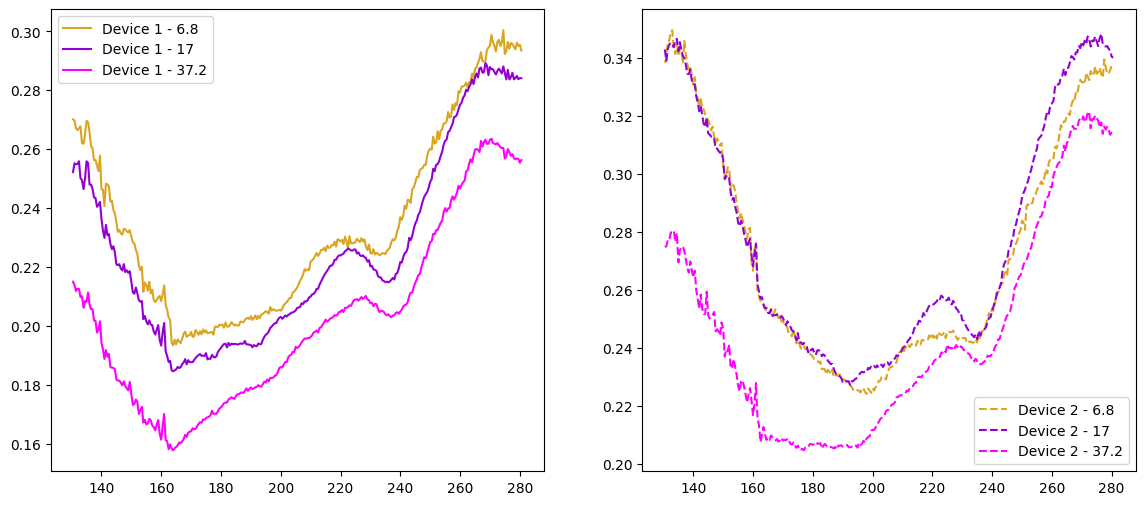

In [3]:
## Loading the data
ms.ResetColorCycle()
name1ps = "8deg/Reflectance_7_pol00_HPK1#.txt"

fnames_refData_A1 = ["8deg/Reflectance_7_pol00_HPK1#.txt"]
fnames_refData_A2 = ["8deg/Reflectance_7_pol90_HPK2#.txt"]
fnames_refData_B1 = ["18deg/Reflectance_HPK1#_pol0_17.txt", "18deg/Reflectance_HPK1#_pol90_17.txt"]
fnames_refData_B2 = ["18deg/Reflectance_HPK2#_pol0_17.txt", "18deg/Reflectance_HPK2#_pol90_17.txt"]
fnames_refData_C1 = ["38deg/Reflectance_HPK1#_pol0_37.txt", "38deg/Reflectance_HPK1#_pol90_37.txt"]
fnames_refData_C2 = ["38deg/Reflectance_HPK2#_pol0_37.txt", "38deg/Reflectance_HPK2#_pol90_37.txt"]

refData_angles = [6.8, 17, 37.2]

refData1 = [] # give the layout d1 = [x1, r1]
refData2 = []

## data for first quad (50um)
x, r = np.genfromtxt(PROPATH+"/literatureData/ref_data_guofu/"+fnames_refData_A1[0], skip_header= 0, delimiter=" ", unpack=True)
refData1.append([x, r])

xs, rs = np.genfromtxt(PROPATH+"/literatureData/ref_data_guofu/"+fnames_refData_B1[0], skip_header= 0, delimiter=" ", unpack=True)
xp, rp = np.genfromtxt(PROPATH+"/literatureData/ref_data_guofu/"+fnames_refData_B1[1], skip_header= 0, delimiter=" ", unpack=True)
r = (rs + rp)/2
refData1.append([xs, r])

xs, rs = np.genfromtxt(PROPATH+"/literatureData/ref_data_guofu/"+fnames_refData_C1[0], skip_header= 0, delimiter=" ", unpack=True)
xp, rp = np.genfromtxt(PROPATH+"/literatureData/ref_data_guofu/"+fnames_refData_C1[1], skip_header= 0, delimiter=" ", unpack=True)
r = (rs + rp)/2
refData1.append([xs, r])

## doing second quad (75um)
x, r = np.genfromtxt(PROPATH+"/literatureData/ref_data_guofu/"+fnames_refData_A2[0], skip_header= 0, delimiter=" ", unpack=True)
refData2.append([x, r])

xs, rs = np.genfromtxt(PROPATH+"/literatureData/ref_data_guofu/"+fnames_refData_B2[0], skip_header= 0, delimiter=" ", unpack=True)
xp, rp = np.genfromtxt(PROPATH+"/literatureData/ref_data_guofu/"+fnames_refData_B2[1], skip_header= 0, delimiter=" ", unpack=True)
r = (rs + rp)/2
refData2.append([xs, r])

xs, rs = np.genfromtxt(PROPATH+"/literatureData/ref_data_guofu/"+fnames_refData_C2[0], skip_header= 0, delimiter=" ", unpack=True)
xp, rp = np.genfromtxt(PROPATH+"/literatureData/ref_data_guofu/"+fnames_refData_C2[1], skip_header= 0, delimiter=" ", unpack=True)
r = (rs + rp)/2
refData2.append([xs, r])

for r1, r2 in zip(refData1, refData2):
    r1[1] /= 100.
    r2[1] /= 100.


#### plotting and adjusting the data
masking = 130

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 6))
for i, (d1, d2) in enumerate(zip(refData1, refData2)):
    
    x1, r1 = d1
    x2, r2 = d2
    
    if isinstance(masking, float) or isinstance(masking, int):
        mask1 = (x1 > masking)
        mask2 = (x2 > masking)
        x1, r1 = x1[mask1], r1[mask1]
        x2, r2 = x2[mask2], r2[mask2]
    
    ax1.plot(x1, r1, color = ms.GetNextColor(), label = f"Device 1 - {refData_angles[i]}")
    ax2.plot(x2, r2, color = ms.GetNextColor(1), linestyle = "--", label = f"Device 2 - {refData_angles[i]}")


ax1.legend()
ax2.legend()
plt.show()

In [4]:
# general, no nuisance parameter fitting function(s)
def ssGetNames(func):
    return inspect.getfullargspec(func).args

# class myParameter():
#     def __init__(self, name, value, error):
#         self.name = name
#         self.value = value
#         self.bounds = None
#         self.error = error

def ResultDict(fitResult, x0Names):
    resultDict = {}
    for i, key in enumerate(x0Names):
        value = fitResult.x[i]
        error = np.sqrt(fitResult.hess_inv[i, i])
        mpar = myParameter(name=key, value = value, error = error)
        resultDict[key] = mpar


# order x0 has to match the ordering in functionToFit
# therefore, this sorts the floating parameters into the correct order
def buildX0(floatDict, functionToFit):
    x0 = []
    x0Names = []
    for key in ssGetNames(functionToFit):
        if key in floatDict.keys():
            x0.append(floatDict[key])
            x0Names.append(key)
    return x0, x0Names

# ditto as above, but sorts the bounds
def buildX0_bounds(floatBoundsDict, functionToFit):
    bounds = []
    for key in ssGetNames(functionToFit):
        if key in floatBoundsDict.keys():
            bounds.append((floatBoundsDict[key][0], floatBoundsDict[key][1]))
    return bounds

# returns a copy of dict1 minus dict2 keys
def dictKeySubtraction(dict1, dict2):
    return {key: dict1[key] for key in dict1.keys() - dict2.keys()}

def listSubtraction_orderd(list1, list2):
    return [x for x in list1 if x not in list2]

# nuisance map adds extra values. Need to correct for them
# nuisance pars need to be the last values in x0
nuisMap = {"sd1": "scaleDown", "sd2": "scaleDown"}

def genericResiduals(x0, fixedArgs_dict, dataHeaders, dataObj, functionToFit, verbose = False):

    # sorted, ordered lists of args
    allArgs = ssGetNames(functionToFit)
    nonDataArgs = listSubtraction_orderd(allArgs, dataHeaders)
    missingFloatArgs = listSubtraction_orderd(nonDataArgs, fixedArgs_dict.keys()) # this is the ordered keys that x0 correspond to
    
    print("all args minus data", nonDataArgs) if verbose else None
    print("missing args", missingFloatArgs) if verbose else None
    
    ## length testing, ensuring enough vars are passed
    if len(x0) + len(fixedArgs_dict) != len(nonDataArgs):
        print("missing or extra args passed, len(x0) + len(fixedDict) != len(argsNeeded)")
        print("lens:", len(x0) + len(fixedArgs_dict), len(allArgs))
    
    # see what keys are missing from fixed list (these are in x0)
    if len(x0) != len(missingFloatArgs):
        print("missing args to function does not match x0!")
        print(len(missingFloatArgs), len(x0))
    
    # create a new dictionary with the missing keys and values from x0
    fullArgDict = fixedArgs_dict.copy()
    for i, key in enumerate(missingFloatArgs):
        fullArgDict[key] = x0[i]
    
    if len(dataHeaders) < 2:
        print("Not enough data headers supplied!\nneed at least 2 (x and y) or other values will get broken")
    
    ## Data loop
    resSum = 0
    for i, oneD in enumerate(dataObj):
        x = oneD[0]
        y = oneD[1]
        
        # things like voltage, theta, etc here
        dataXdict = {dataHeaders[0]: x}
        # this skips the y values that are in data (of course!)
        otherDataDict = {key: oneD[i+2] for i, key in enumerate(dataHeaders[2:])}
        
        print(f"otherDataDict {i}", otherDataDict, "\n") if verbose else None
        # print(f"dataXdict {i}", dataXdict, "\n") if verbose else None
        print(f"fullArgDict {i}", fullArgDict, "\n") if verbose else None
        
        yFit = functionToFit(**fullArgDict, **dataXdict, **otherDataDict)
        
        resSum += np.sum((y - yFit)**2)
    
    return resSum
    
    

all args minus data ['a', 'b', 'c']
missing args ['c']
otherDataDict 0 {} 

fullArgDict 0 {'b': 0, 'a': 1.0, 'c': 5} 

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 11.73025650697521
        x: [ 5.537e+00]
      nit: 3
      jac: [-1.192e-06]
 hess_inv: [[ 8.333e-03]]
     nfev: 8
     njev: 4
{'c': 5.536990615100724}


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/scipy/optimize/_minimize.py:569: RuntimeWarning: Method BFGS cannot handle bounds.
  warn('Method %s cannot handle bounds.' % method,


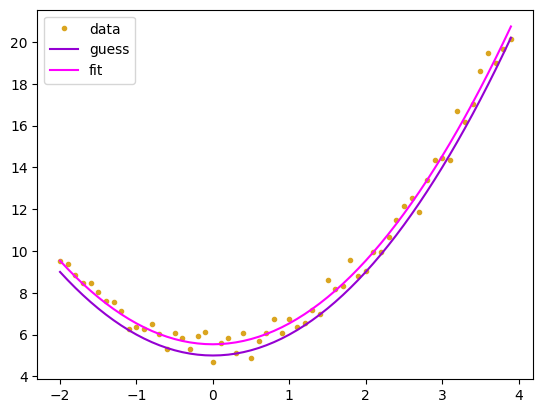

In [5]:
## Testing/example no nuisance par fitting
def testFunctionA(x, a=0, b=0, c=10):
    # print("a", a, "b", b, "c", c)
    return a*x**2 + b*x + c

ssGetNames(testFunctionA)

### -- How to use the code above --- ###

## Step 1: setup names and variables    
# if its looped over (changes for datasets, put it in here)
dataArgNames = ["x", "y"] # data headers. second isn't used but should be included

# fixed variables
fixedDict = {"b":0, "a":1.0}

# float variables
floatDict = {"c":5} # guesses
floatBounds = {"a":(0, 10)}

# dataArgNames + fixedDict + floatDict should have all the things that the fit function accepts, plus one extra for the input y data
# this should be checked in my residuals but maybe isn't
# xx need to include errors in residual and data object that gets passed around

## Step 2: sort floating parameters into ordered array and bounds
x0, x0Names = buildX0(floatDict, testFunctionA)
x0Bounds = buildX0_bounds(floatBounds, testFunctionA)

# Step 3: organize your data. It NEEDS to be formatted as [dataset1[x, y, whatever else], dataset2[x, y, whatever else], ...]
xData = np.arange(-2, 4, 0.1)
yData = 0.5+testFunctionA(x=xData, **fixedDict, **floatDict) + np.random.normal(scale=0.5, size=len(xData))
dataObj = [[xData, yData]]

## Step 4: test your function, and residual function
testFunctionA(x=xData, **fixedDict, **floatDict)
genericResiduals(x0=x0, fixedArgs_dict=fixedDict, dataHeaders=dataArgNames, dataObj=dataObj, functionToFit=testFunctionA, verbose=True)

## Step 5: run the fit
result = opt.minimize(genericResiduals, x0=x0, bounds = x0Bounds, args=(fixedDict, dataArgNames, dataObj, testFunctionA), method='BFGS')
print(result)
resultDict = {x0Names[i]: result.x[i] for i in range(len(x0Names))}
print(resultDict)

## xx doesn't work yet
# resultPar = ResultDict(fitResult=result, x0Names=x0Names)

# resultErrors = {x0Names[i]: np.sqrt(result.hess_inv[i, i]) for i in range(len(x0Names))}
# print(resultErrors)

## Step 6: plot the results!
plt.plot(xData, yData, label = "data", marker=".", linestyle="none")
plt.plot(xData, testFunctionA(x=xData, **fixedDict, **floatDict), label = "guess")
plt.plot(xData, testFunctionA(x=xData, **fixedDict, **resultDict), label = "fit")

plt.legend()
plt.show()

In [6]:
# building different datasets

dataNames = ["wlen", "Ref", "theta1", "FF"] # data headers. second isn't used but should be included

## Data must be [wlen, Ref, theta1, FF]
FF1 = 0.6
FF2 = 0.7

# data for 2 par fitting (toxide, scaleDown)
refDataObj_nuis2 = []
data2Include=len(refData1)-1
for i, (x, y) in enumerate(refData1[:data2Include]):
    oneD = [x, y, refData_angles[i], FF1]
    refDataObj_nuis2.append(oneD)
for i, (x, y) in enumerate(refData2[:data2Include]):
    oneD = [x, y, refData_angles[i], FF2]
    refDataObj_nuis2.append(oneD)

# data for independent dataset no nuisance pars (t1, sd1) (t2, sd2)
refData1_nuis1 = []
refData2_nuis1 = []
for i, (x, y) in enumerate(refData1[:data2Include]):
    oneD = [x, y, refData_angles[i], FF1]
    refData1_nuis1.append(oneD)
for i, (x, y) in enumerate(refData2[:data2Include]):
    oneD = [x, y, refData_angles[i], FF2]
    refData2_nuis1.append(oneD)

# for 1:1 fitting (toxide, NdataXscaleDown)
refData_nuisanceN = [] # for 1:1 fitting
for i, (x, y) in enumerate(refData1):
    oneD = [x, y, refData_angles[i], FF1]
    refData_nuisanceN.append(oneD)
for i, (x, y) in enumerate(refData2):
    oneD = [x, y, refData_angles[i], FF2]
    refData_nuisanceN.append(oneD)

# data for independent device fitting, toxide1, Ndata1xScaleDown1
refNuisane_1Ndata = []
refNuisane_2Ndata = []
for i, (x, y) in enumerate(refData1):
    oneD = [x, y, refData_angles[i], FF1]
    refNuisane_1Ndata.append(oneD)
for i, (x, y) in enumerate(refData2):
    oneD = [x, y, refData_angles[i], FF2]
    refNuisane_2Ndata.append(oneD)

---
### Single nuisance par - all data (single scale down)

In [7]:
## Fitting no nuisance pars
dhFBK = OpticsData(oxideDataPath=PROPATH+"/opticsData/GoodMerged/silicon_dioxide-merged-nEXOFBK_k.txt")
OpticsData.ResetInstance()

fixedDict = {'gausSigma':None, "dh":None}
floatDict = {"toxide":15, "scaleDown":0.3}
floatBounds = {"toxide":(0.5, 250), "scaleDown":(0, 1)}

x0, x0Names = buildX0(floatDict, func_Ref)
print(x0)
x0Bounds = buildX0_bounds(floatBounds, func_Ref)

print(len(refDataObj_nuis2))
genericResiduals(x0=x0, fixedArgs_dict=fixedDict, dataHeaders=dataNames, dataObj=refDataObj_nuis2, functionToFit=func_Ref, verbose=False)

fitOpts={'maxiter': 10000, 'ftol': 1e-9, 'gtol': 1e-9, 'eps': 1e-4}
#fitOpts={'maxiter': 100000, 'eps': 1e-8}
result = opt.minimize(genericResiduals, x0=x0, bounds = x0Bounds, args=(fixedDict, dataNames, refDataObj_nuis2, func_Ref), jac="3-point", method='L-BFGS-B', options=fitOpts)
print(result)

def GetErrorFromHess(resHessProduct):
    inv_hess = resHessProduct.todense()
    # hess = np.linalg.inv(inv_hess)
    return np.sqrt(np.diag(inv_hess))
def GetResDict(fitResult, x0Names):
    return {x0Names[i]: fitResult.x[i] for i in range(len(x0Names))}
resultDict = GetResDict(result, x0Names)

print(resultDict)
print("Errors:", GetErrorFromHess(result.hess_inv))

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_crystalline_lithoAndSchinke_merged.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/opticsData/GoodMerged/silicon_dioxide-merged-nEXOFBK_k.txt
loaded and interpolated successfully.
-----------------------------
[15, 0.3]
4
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_crystalline_lithoAndSchinke_merged.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMe

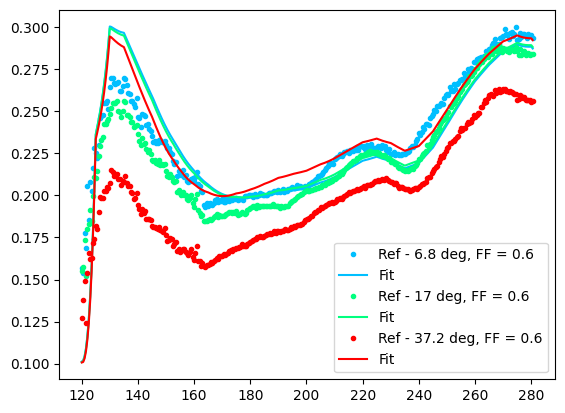

In [8]:
ms.ResetColorCycle(2)
for oneD in refNuisane_1Ndata:
    x = oneD[0]
    y = oneD[1]
    theta = oneD[2]
    FF = oneD[3]
    yFit = func_Ref(x, theta1=theta, FF=FF, **resultDict, **fixedDict)
    
    plt.plot(x, y, marker=".", color=ms.GetNextColor(), linestyle="none", label = f"Ref - {theta} deg, FF = {FF}")
    plt.plot(x, yFit, color=ms.GetNextColor(1), label = f"Fit")

plt.legend()
plt.show()

In [9]:
# for doing the full reflectivity fit, I need a wrapper function that takes two nuisane parameters.

# add nuisance parameters and mapping to my function
# a - all data (no nuisance pars), share t
# aa- fully independent (two t values)
# b - all data (1 nuisance per device)
# c - all data (1 nuisance for each dataset)
# d - discard high angle data --> trench obstruction
        # couldn't measure angle vs diffusion in paper

# try some from above with FBK k data

# try again with MINUIT


# add in Hamamatsu data? extra global fit?



---
### Per dataset - single nuisance

In [10]:
## Fitting no nuisance pars
fixedDict = {'gausSigma':2, "dh":None}
floatDict = {"toxide":15, "scaleDown":0.3}
floatBounds = {"toxide":(0.5, 250), "scaleDown":(0, 1)}

x0, x0Names = buildX0(floatDict, func_Ref)
x0Bounds = buildX0_bounds(floatBounds, func_Ref)

## fitting dataset 1
genericResiduals(x0=x0, fixedArgs_dict=fixedDict, dataHeaders=dataNames, dataObj=refData1_nuis1, functionToFit=func_Ref, verbose=False)

fitOpts={'maxiter': 10000, 'ftol': 1e-9, 'gtol': 1e-9, 'eps': 1e-4}
#fitOpts={'maxiter': 100000, 'eps': 1e-8}
result1 = opt.minimize(genericResiduals, x0=x0, bounds = x0Bounds, args=(fixedDict, dataNames, refData1_nuis1, func_Ref), jac="3-point", method='L-BFGS-B', options=fitOpts)
result2 = opt.minimize(genericResiduals, x0=x0, bounds = x0Bounds, args=(fixedDict, dataNames, refData2_nuis1, func_Ref), jac="3-point", method='L-BFGS-B', options=fitOpts)
print(result1)
print("Errors:", GetErrorFromHess(result1.hess_inv))
print("--------------")
print(result2)
print("Errors:", GetErrorFromHess(result2.hess_inv))

resultDict1 = GetResDict(result1, x0Names)
print(resultDict1)

resultDict2 = GetResDict(result2, x0Names)
print(resultDict2)

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 0.11188917465408368
        x: [ 1.601e+01  2.757e-01]
      nit: 6
      jac: [-8.922e-10  7.153e-08]
     nfev: 60
     njev: 12
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>
Errors: [4.08527983 0.08805615]
--------------
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 0.12870938863460385
        x: [ 1.881e+01  2.524e-01]
      nit: 7
      jac: [-4.053e-10  3.101e-08]
     nfev: 65
     njev: 13
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>
Errors: [3.95296903 0.0754327 ]
{'toxide': 16.01437744231845, 'scaleDown': 0.27566513865217657}
{'toxide': 18.805654421039133, 'scaleDown': 0.25239402993821974}


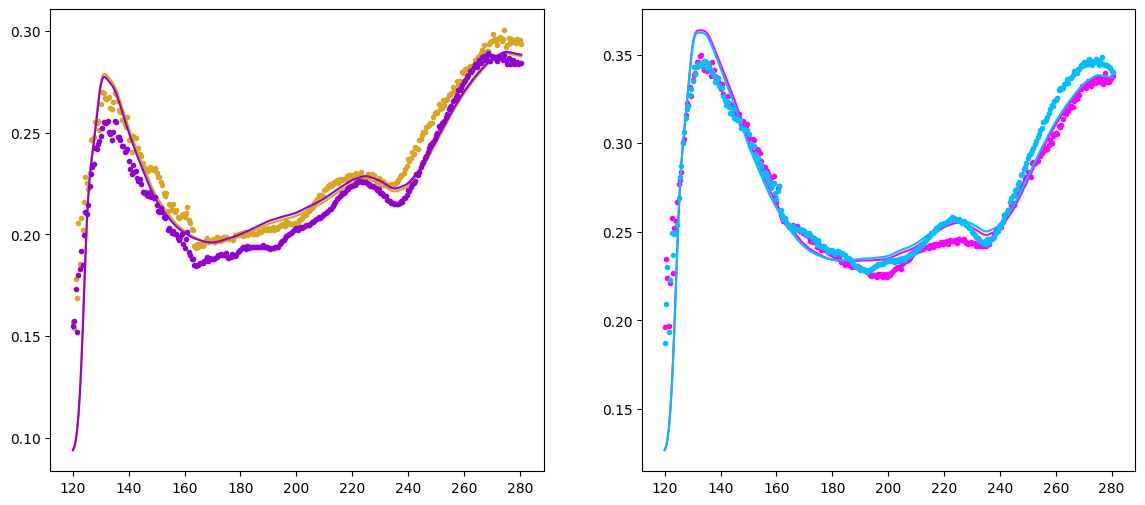

In [11]:
## plot result

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 6))
for oneD in refData1_nuis1:
    x = oneD[0]
    y = oneD[1]
    theta = oneD[2]
    FF = oneD[3]
    yFit = func_Ref(x, theta1=theta, FF=FF, **resultDict1, **fixedDict)
    
    ax1.plot(x, y, marker=".", color = ms.GetNextColor(), linestyle="none", label = f"Ref - {theta} deg, FF = {FF}")
    ax1.plot(x, yFit, color = ms.GetNextColor(1), label = f"Fit")
    
for oneD in refData2_nuis1:
    x = oneD[0]
    y = oneD[1]
    theta = oneD[2]
    FF = oneD[3]
    yFit = func_Ref(x, theta1=theta, FF=FF, **resultDict2, **fixedDict)
    
    ax2.plot(x, y, marker=".", color = ms.GetNextColor(), linestyle="none", label = f"Ref - {theta} deg, FF = {FF}")
    ax2.plot(x, yFit, color = ms.GetNextColor(1), label = f"Fit")

---
### Single thickness, all Nuisance (scaleDown x N)

In [12]:
ssGetNames(func_Ref)

['wlen', 'theta1', 'toxide', 'FF', 'scaleDown', 'gausSigma', 'dh']

In [13]:
def residualScore(ydata, yfit):
    return np.sum((ydata - yfit)**2)
    

## this is poorly coded
# data must be x, y, theta, FF
def refResiduals_nuisace_1to1(tOxide, fixedArgs_dict, dataAll, nuisanceOutput, verbose = False, ax1=None, ax2=None):
    res = 0
    thisNuisance = []
    for i, oneD in enumerate(dataAll):
        x = oneD[0]
        y = oneD[1]
        theta = oneD[2]
        FF = oneD[3]
        
        # yFit_pure = func_Ref(wlen=x, theta1=theta, toxide=tOxide, FF=FF, scaleDown=0.3, **fixedArgs_dict)
        # scaleDownGuess = 1-np.mean(y/yFit_pure)
        
        # high granular
        scaleXs = np.arange(0, 1, 0.05)
        scores = np.array([residualScore(y, func_Ref(wlen=x, theta1=theta, toxide=tOxide, FF=FF, scaleDown=sd, **fixedArgs_dict)) for sd in scaleXs])
        minIndex = np.argmin(scores)
        highGrainMin = scaleXs[minIndex]
        print("hi grain min:", highGrainMin) if verbose else None
        
        # more granular
        scaleXs = np.arange(highGrainMin-0.05, highGrainMin+0.05, 0.001)
        scores = np.array([residualScore(y, func_Ref(wlen=x, theta1=theta, toxide=tOxide, FF=FF, scaleDown=sd, **fixedArgs_dict)) for sd in scaleXs])
        minIndex = np.argmin(scores)
        scaleDownMin = scaleXs[minIndex]
        
        fFit = func_Ref(wlen=x, theta1=theta, toxide=tOxide, FF=FF, scaleDown=scaleDownMin, **fixedArgs_dict)
        
        if verbose:
            print("scale mins: ", highGrainMin, scaleDownMin)
            # ax1.vlines(highGrainMin, 0, max(scores), color="r", linestyle="--")
            ax1.vlines(scaleDownMin, 0, max(scores), color=ms.allColsStr[i], linestyle="--")
            ax1.plot(scaleXs, scores)
            
            ax2.plot(x, y, color = ms.allColsStr[i], marker=".", markersize = 0.5, alpha = 0.5, linestyle="none")
            # ax2.plot(x, yFit_pure, color = ms.allColsStr[i], label = "pure")
            ax2.plot(x, fFit,alpha = 0.5, label = "minimized scaling")
        
        thisNuisance.append(scaleDownMin)
        
        score = residualScore(y, fFit)
        res += score
    nuisanceOutput.append(thisNuisance)
    return res

In [14]:
## Calculating sparce
nuisance1to1_sparse = []
xThickValues_sparse = np.concatenate((np.arange(0.0, 50, 5), np.arange(50, 2000, 100)), )
scores_sparse = [refResiduals_nuisace_1to1(tOxide=t, fixedArgs_dict={}, dataAll=refData_nuisanceN, nuisanceOutput=nuisance1to1_sparse, verbose=False) for t in xThickValues_sparse]
print("done sparse search")

done sparse search


Text(0, 0.5, 'Residual score')

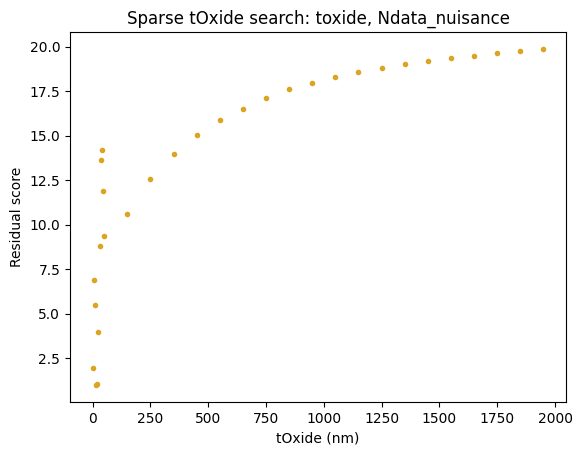

In [15]:
plt.plot(xThickValues_sparse, scores_sparse, linestyle="None", marker=".")

plt.title("Sparse tOxide search: toxide, Ndata_nuisance")
plt.xlabel("tOxide (nm)")
plt.ylabel("Residual score")

In [16]:
## Calculating finer search
nuisance1to1 = []
# refResiduals_nuisace_1to1((16.5), fixedArgs_dict={}, dataAll=refData_nuisanceN, nuisanceOutput=nuisance1to1, verbose=False)

nuisance1to1_range = []
xThickValues = np.arange(0.0, 80, 2)
scores = [refResiduals_nuisace_1to1(tOxide=t, fixedArgs_dict={}, dataAll=refData_nuisanceN, nuisanceOutput=nuisance1to1_range, verbose=False) for t in xThickValues]
print("done medium grain search")

minThick = xThickValues[np.argmin(scores)]
xThickValues_zoom = np.arange(minThick-1.5, minThick+0.5, 0.1)
scores_zoom = [refResiduals_nuisace_1to1(tOxide=t, fixedArgs_dict={}, dataAll=refData_nuisanceN, nuisanceOutput=nuisance1to1, verbose=False) for t in xThickValues_zoom]
print("done fine grain search")

newMin_fitC = xThickValues_zoom[np.argmin(scores_zoom)]
print(f"min Thickness = {newMin_fitC:0.2f} nm")

done medium grain search
done fine grain search
min Thickness = 17.30 nm


In [17]:
print(len(nuisance1to1_range))

40


peaks at: [ 6. 38. 68.]
min Thickness = 17.30(nm)
40
40


Text(0.5, 0, 'thickness (nm)')

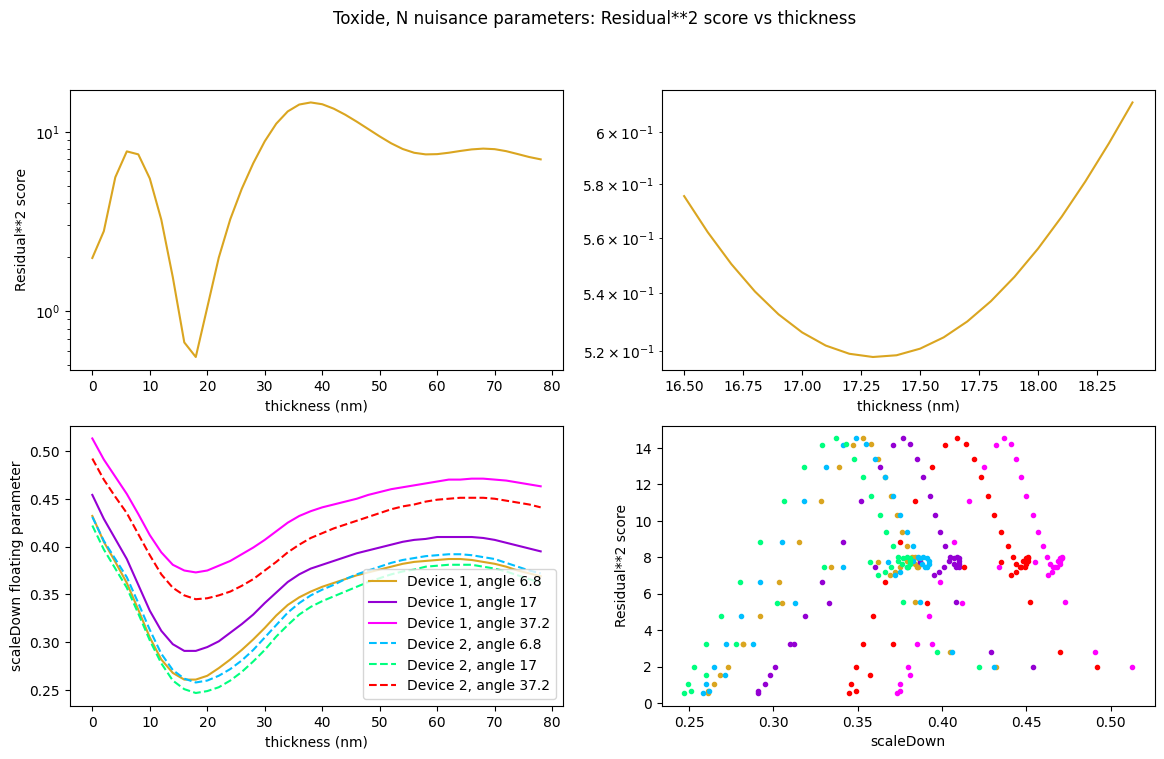

In [18]:
peaks, _ = find_peaks(scores, distance=1)
thickPeaks = xThickValues[peaks]
print("peaks at:", thickPeaks)

newMin_fitC = xThickValues_zoom[np.argmin(scores_zoom)]
print(f"min Thickness = {newMin_fitC:0.2f}(nm)")

## plotting
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize = (14, 8))

ax1.semilogy(xThickValues, scores)
ax2.semilogy(xThickValues_zoom, scores_zoom)

nuisance1to1Plot = np.array(nuisance1to1_range)
for i in range(len(nuisance1to1Plot[0])):
    label = f"Device 1, angle {refData_angles[i]}" if i < 3 else f"Device 2, angle {refData_angles[i-3]}"
    ls = "-" if i < 3 else "--"
    ax3.plot(xThickValues, nuisance1to1Plot[:, i], linestyle = ls, label = label)
    ax4.plot(nuisance1to1Plot[:, i], scores, marker = ".", linestyle="none")

ax3.legend()
ax3.set_ylabel("scaleDown floating parameter")
ax3.set_xlabel("thickness (nm)")
print(len(nuisance1to1Plot))
print(len(xThickValues))
 
ax4.set_xlabel("scaleDown")
ax4.set_ylabel("Residual**2 score")

fig.suptitle("Toxide, N nuisance parameters: Residual**2 score vs thickness")
ax1.set_ylabel("Residual**2 score")
ax1.set_xlabel("thickness (nm)")
# ax2.set_ylabel("Residual**2 score")
ax2.set_xlabel("thickness (nm)")

thickPeaks [ 6. 38. 68.]
hi grain min: 0.35000000000000003
scale mins:  0.35000000000000003 0.3530000000000001
hi grain min: 0.4
scale mins:  0.4 0.37700000000000006
hi grain min: 0.45
scale mins:  0.45 0.43700000000000006
hi grain min: 0.35000000000000003
scale mins:  0.35000000000000003 0.3490000000000001
hi grain min: 0.35000000000000003
scale mins:  0.35000000000000003 0.3370000000000001
hi grain min: 0.4
scale mins:  0.4 0.4090000000000001


Text(0.5, 0, 'Wavelength (nm)')

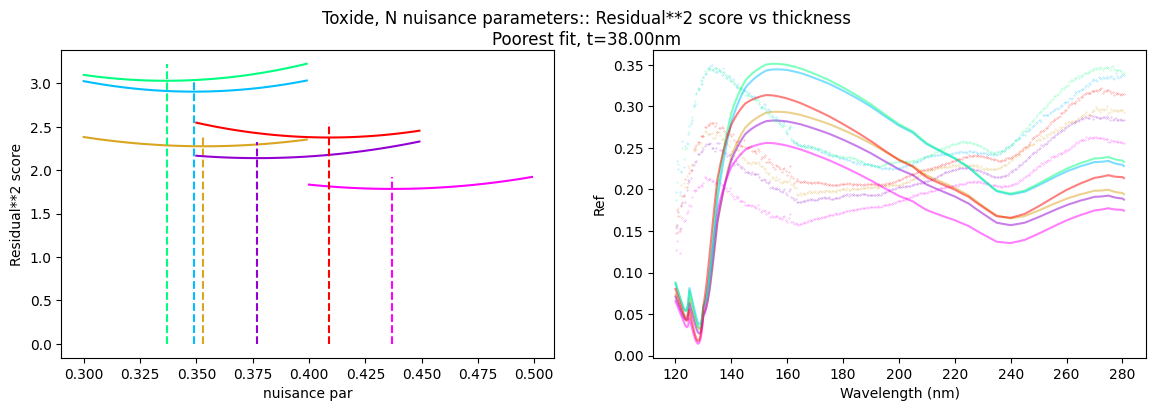

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 4))
print("thickPeaks", thickPeaks)
bigPeak = thickPeaks[1]

refResiduals_nuisace_1to1(bigPeak, fixedArgs_dict={}, dataAll=refData_nuisanceN, nuisanceOutput=[], verbose=True, ax1=ax1, ax2=ax2)

fig.suptitle(f"Toxide, N nuisance parameters:: Residual**2 score vs thickness\nPoorest fit, t={bigPeak:.2f}nm")
ax1.set_ylabel("Residual**2 score")
ax1.set_xlabel("nuisance par")
ax2.set_ylabel("Ref")
ax2.set_xlabel("Wavelength (nm)")

thickPeaks [ 6. 38. 68.]
hi grain min: 0.25
scale mins:  0.25 0.26000000000000006
hi grain min: 0.30000000000000004
scale mins:  0.30000000000000004 0.2900000000000001
hi grain min: 0.35000000000000003
scale mins:  0.35000000000000003 0.3730000000000001
hi grain min: 0.25
scale mins:  0.25 0.25900000000000006
hi grain min: 0.25
scale mins:  0.25 0.24800000000000005
hi grain min: 0.35000000000000003
scale mins:  0.35000000000000003 0.3460000000000001


Text(0.5, 0, 'Wavelength (nm)')

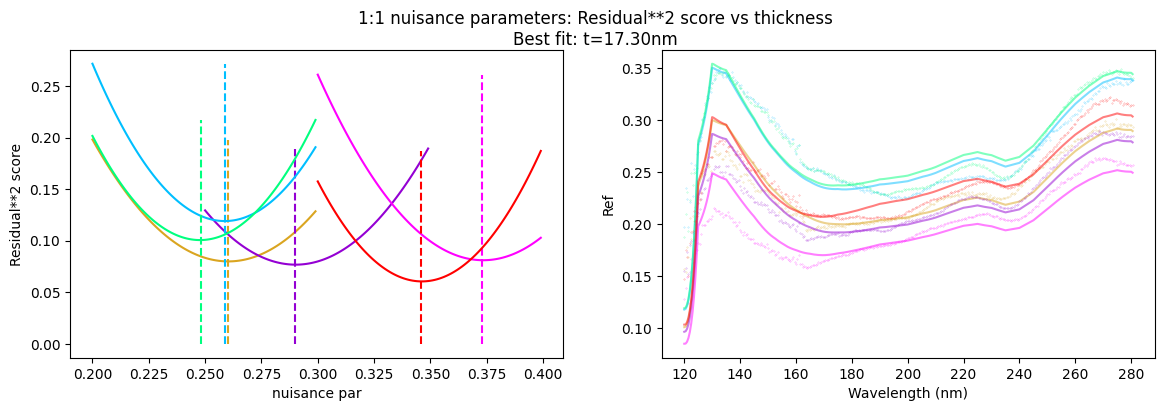

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 4))
print("thickPeaks", thickPeaks)
bigPeak = thickPeaks[1]
nuisanceHere = []
refResiduals_nuisace_1to1(newMin_fitC, fixedArgs_dict={}, dataAll=refData_nuisanceN, nuisanceOutput=nuisanceHere, verbose=True, ax1=ax1, ax2=ax2)

fig.suptitle(f"1:1 nuisance parameters: Residual**2 score vs thickness\nBest fit: t={newMin_fitC:0.2f}nm")
ax1.set_ylabel("Residual**2 score")
ax1.set_xlabel("nuisance par")
ax2.set_ylabel("Ref")
ax2.set_xlabel("Wavelength (nm)")



[[0.26000000000000006, 0.2900000000000001, 0.3730000000000001, 0.25900000000000006, 0.24800000000000005, 0.3460000000000001]]


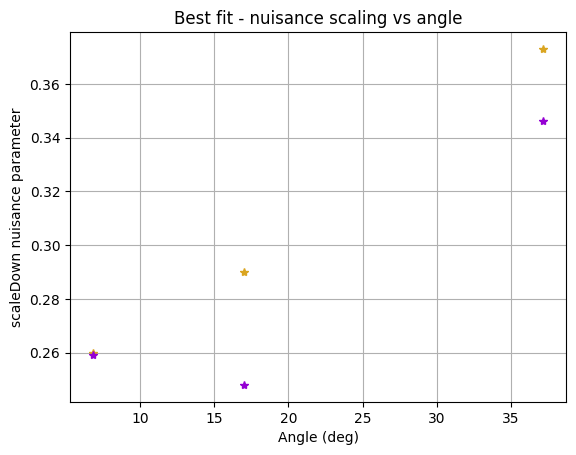

In [21]:
## plot nuisance pars

print(nuisanceHere)
plt.plot(refData_angles, nuisanceHere[0][0:3], marker = "*", linestyle = "none", label = "Device 1")
plt.plot(refData_angles, nuisanceHere[0][3:], marker = "*", linestyle = "none", label = "Device 2")

plt.title("Best fit - nuisance scaling vs angle")
plt.xlabel("Angle (deg)")
plt.ylabel("scaleDown nuisance parameter")

plt.grid()
plt.show()

---
### Per device, all nuisance

In [22]:
## doing the same for the independent device fitting
xThickValues = np.arange(14.0, 20., 0.1)
scores1 = [refResiduals_nuisace_1to1(tOxide=t, fixedArgs_dict={}, dataAll=refNuisane_1Ndata, nuisanceOutput=[], verbose=False) for t in xThickValues]
print("data 1: done medium grain search")

scores2 = [refResiduals_nuisace_1to1(tOxide=t, fixedArgs_dict={}, dataAll=refNuisane_2Ndata, nuisanceOutput=[], verbose=False) for t in xThickValues]
print("data2: done medium grain search")

data1_min = xThickValues[np.argmin(scores1)]
print(f"data1 - min Thickness = {data1_min:0.2f} nm")

data2_min = xThickValues[np.argmin(scores2)]
print(f"data2 - min Thickness = {data2_min:0.2f} nm")

data 1: done medium grain search
data2: done medium grain search
data1 - min Thickness = 15.90 nm
data2 - min Thickness = 18.40 nm


In [23]:
# running with results
nuisance_data1_1to1 = []
nuisance_data2_1to1 = []
refResiduals_nuisace_1to1(tOxide=data1_min, fixedArgs_dict={}, dataAll=refNuisane_1Ndata, nuisanceOutput=nuisance_data1_1to1, verbose=False)
refResiduals_nuisace_1to1(tOxide=data2_min, fixedArgs_dict={}, dataAll=refNuisane_2Ndata, nuisanceOutput=nuisance_data2_1to1, verbose=False)

print(nuisance_data1_1to1)
print(nuisance_data2_1to1)

[[0.26100000000000007, 0.2910000000000001, 0.37500000000000006]]
[[0.25800000000000006, 0.24700000000000005, 0.3450000000000001]]


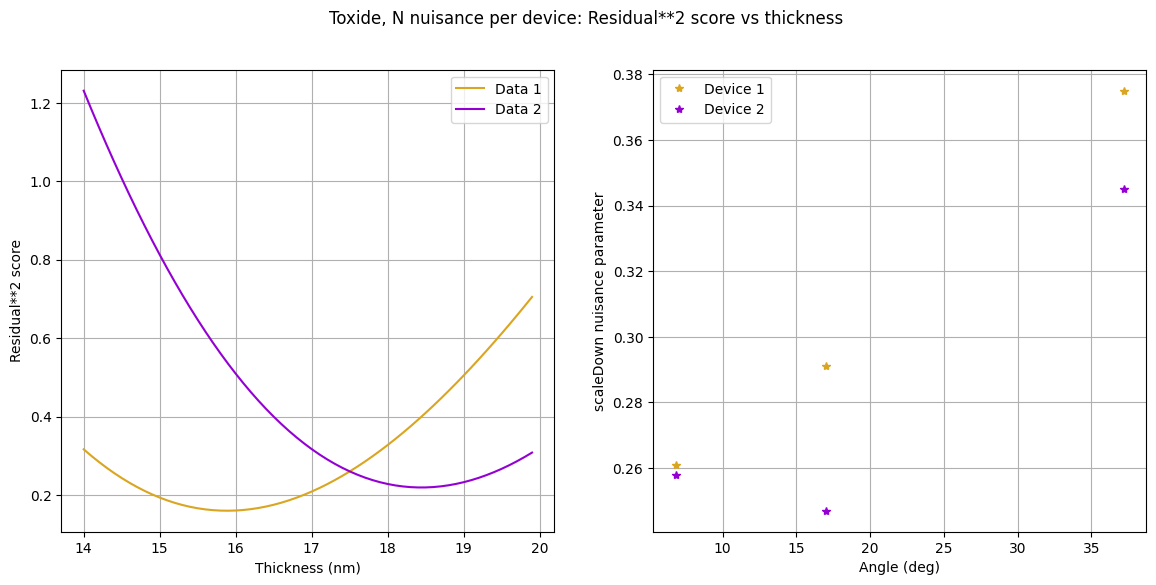

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 6))

ax1.plot(xThickValues, scores1, label = "Data 1")
ax1.plot(xThickValues, scores2, label = "Data 2")

ax2.plot(refData_angles, nuisance_data1_1to1[0], marker = "*", linestyle = "none", label = "Device 1")
ax2.plot(refData_angles, nuisance_data2_1to1[0], marker = "*", linestyle = "none", label = "Device 2")

fig.suptitle("Toxide, N nuisance per device: Residual**2 score vs thickness")
ax1.set_xlabel("Thickness (nm)")
ax1.set_ylabel("Residual**2 score")
ax1.grid()
ax1.legend()

ax2.set_ylabel("scaleDown nuisance parameter")
ax2.set_xlabel("Angle (deg)")
ax2.grid()
ax2.legend()

hi grain min: 0.25
scale mins:  0.25 0.26100000000000007
hi grain min: 0.30000000000000004
scale mins:  0.30000000000000004 0.2910000000000001
hi grain min: 0.4
scale mins:  0.4 0.37500000000000006
hi grain min: 0.25
scale mins:  0.25 0.25800000000000006
hi grain min: 0.25
scale mins:  0.25 0.24700000000000005
hi grain min: 0.35000000000000003
scale mins:  0.35000000000000003 0.3450000000000001


Text(0.5, 0, 'Wavelength (nm)')

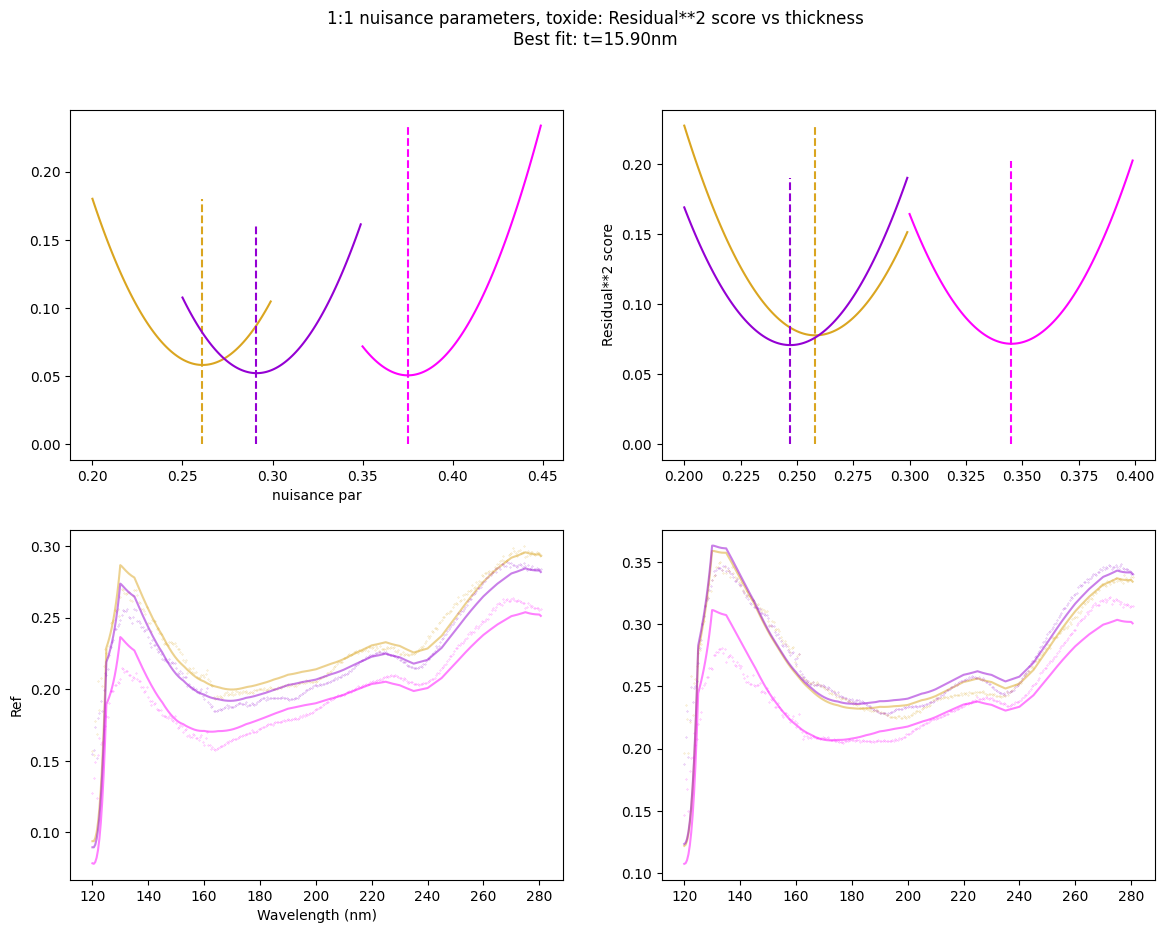

In [25]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize = (14, 10))
nuisanceHereD = []
refResiduals_nuisace_1to1(data1_min, fixedArgs_dict={}, dataAll=refNuisane_1Ndata, nuisanceOutput=nuisanceHereD, verbose=True, ax1=ax1, ax2=ax3)

refResiduals_nuisace_1to1(data2_min, fixedArgs_dict={}, dataAll=refNuisane_2Ndata, nuisanceOutput=nuisanceHereD, verbose=True, ax1=ax2, ax2=ax4)

fig.suptitle(f"1:1 nuisance parameters, toxide: Residual**2 score vs thickness\nBest fit: t={data1_min:0.2f}nm")
ax2.set_ylabel("Residual**2 score")
ax1.set_xlabel("nuisance par")
ax3.set_ylabel("Ref")
ax3.set_xlabel("Wavelength (nm)")

---
### All thickness results

In [26]:
fitA = result.x[0]
print("single t, scale down, fit A")
print(f"\t{fitA:0.2f} nm")

fitB1 = result1.x[0]
fitB2 = result2.x[0]
print("single t, scale down per device, fit B")
print(f"\t{fitB1:0.2f} nm", f"{fitB2:0.2f} nm")

fitC = newMin_fitC
print("single t, scale down per dataset, fit C")
print(f"\t{fitC:0.2f} nm")

fitD1 = data1_min
fitD2 = data2_min
print("single t, scale down per dataset per device, fit D")
print(f"\t{fitD1:0.2f} nm", f"{fitD2:0.2f} nm")

averageT = np.mean([fitA, fitB1, fitB2, fitC, fitD1, fitD2])
print(f"\naverage thickness = {averageT:0.2f} nm")

dev1_thick = np.mean([fitB1, fitD1])
dev2_thick = np.mean([fitB2, fitD2])
print(f"average thickness per device = {dev1_thick:0.2f} nm, {dev2_thick:0.2f} nm")

single t, scale down, fit A
	17.56 nm
single t, scale down per device, fit B
	16.01 nm 18.81 nm
single t, scale down per dataset, fit C
	17.30 nm
single t, scale down per dataset per device, fit D
	15.90 nm 18.40 nm

average thickness = 17.33 nm
average thickness per device = 15.96 nm, 18.60 nm


---
### Showing Ref equation works for FBK

In [27]:
fnames_fbk1 = ["18deg/Reflectance_LF_pol0_17.txt", "18deg/Reflectance_LF_pol90_17.txt"]
fnames_fbkA = ["193nm/ARR_193nm_pol0_SiO2.txt", "193nm/ARR_193nm_pol90_SiO2.txt"]

xs, rs = np.genfromtxt(PROPATH+"/literatureData/ref_data_guofu/"+fnames_fbkA[0], skip_header= 0, delimiter=" ", unpack=True)
xp, rp = np.genfromtxt(PROPATH+"/literatureData/ref_data_guofu/"+fnames_fbkA[1], skip_header= 0, delimiter=" ", unpack=True)
rs /=100
rp /=100
rfbk = (rs+rp)/2

[1490, 0.2]
[(1000, 2000), (0, 1)]
  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 0.011784080825769405
        x: [ 1.489e+03  1.745e-01]
      nit: 6
      jac: [-7.178e-10  5.221e-10]
     nfev: 65
     njev: 13
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>
{'toxide': 1488.8580040586944, 'scaleDown': 0.17454579067474907}


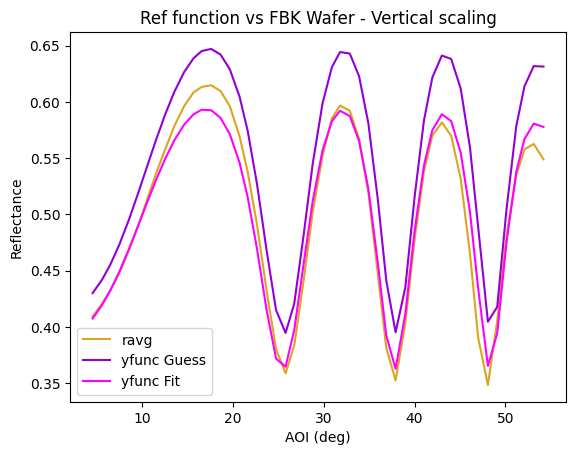

In [28]:
# !! NEED TO ENSURE X IN DATAHEADERS IS IN FUNCTIONS

tFBKguess = 1490
tFloatDict = {"toxide":tFBKguess, "scaleDown":0.2}
tFloatBounds = {"toxide":(1000, 2000), "scaleDown":(0, 1)}

tFixedDict = {"gausSigma":None, "dh":None, "FF":1.0, "wlen":193}
tDataHeader = ["theta1", "ref"]
tDataObj_single = [[xs, rfbk]]

x0, x0Names = buildX0(tFloatDict, func_Ref)
x0Bounds = buildX0_bounds(tFloatBounds, func_Ref)
print(x0)
print(x0Bounds)

yfunc = func_Ref(theta1=xs, wlen=193, toxide=tFBKguess, FF=0.9, scaleDown=0.0, gausSigma=None, dh=None)

# genericResiduals(x0=x0, fixedArgs_dict=tFixedDict, dataHeaders=tDataHeader, dataObj=tDataObj_single, functionToFit=func_Ref, verbose=True)

fitOpts={'maxiter': 10000, 'ftol': 1e-9, 'gtol': 1e-9, 'eps': 1e-4}
tresult = opt.minimize(genericResiduals, x0=x0, bounds = x0Bounds, args=(tFixedDict, tDataHeader, tDataObj_single, func_Ref), jac="3-point", method='L-BFGS-B', options=fitOpts)
print(tresult)
tresultDict = GetResDict(tresult, x0Names)
print(tresultDict)


plt.title("Ref function vs FBK Wafer - Vertical scaling")
plt.plot(xs, rfbk, label="ravg")
plt.plot(xs, yfunc, label="yfunc Guess")
plt.plot(xs, func_Ref(theta1=xs, **tresultDict, **tFixedDict), label="yfunc Fit")

plt.xlabel("AOI (deg)")
plt.ylabel("Reflectance")
plt.legend()
plt.show()

---
### Looking at scaling vs angle (assuming thicknesses from above)


In [29]:
wlens = [128, 165, 175, 193]
r1s = []
r2s = []

fnames_angleA1 = ["128nm/ARR_128nm_pol0_HPK_1.txt", "128nm/ARR_128nm_pol90_HPK_1.txt"]
fnames_angleA2 = ["128nm/ARR_128nm_pol0_HPK_2.txt", "128nm/ARR_128nm_pol90_HPK_2.txt"]

fnames_angleB1 = ["165nm/ARR_165nm_pol0_HPK_1.txt", "165nm/ARR_165nm_pol90_HPK_1.txt"]
fnames_angleB2 = ["165nm/ARR_165nm_pol0_HPK_2.txt", "165nm/ARR_165nm_pol90_HPK_2.txt"]

fnames_angleC1 = ["175nm/ARR_175nm_po00_HPK1#.txt", "175nm/ARR_175nm_po90_HPK1#.txt"]
fnames_angleC2 = ["175nm/ARR_175nm_po00_HPK2#.txt", "175nm/ARR_175nm_po90_HPK2#.txt"]

fnames_angleD1 = ["193nm/ARR_193nm_pol0_HPK_1.txt", "193nm/ARR_193nm_pol90_HPK_1.txt"]
fnames_angleD2 = ["193nm/ARR_193nm_pol0_HPK_2.txt", "193nm/ARR_193nm_pol90_HPK_2.txt"]

# xs, rs = np.genfromtxt(PROPATH+"literatureData/ref_data_guofu/"+fnames_angleA1[0], skip_header= 0, delimiter=" ", unpack=True)
# xp, rp = np.genfromtxt(PROPATH+"literatureData/ref_data_guofu/"+fnames_angleA1[1], skip_header= 0, delimiter=" ", unpack=True)
# rs, rp = rs/100, rp/100
# r = (rs + rp)/2
# r1s.append([r])

for fnames in [fnames_angleA1, fnames_angleB1, fnames_angleC1, fnames_angleD1]:
    print(fnames)
    xs, rs = np.genfromtxt(PROPATH+"/literatureData/ref_data_guofu/"+fnames[0], skip_header= 0, delimiter=" ", unpack=True)
    xp, rp = np.genfromtxt(PROPATH+"/literatureData/ref_data_guofu/"+fnames[1], skip_header= 0, delimiter=" ", unpack=True)
    rs, rp = rs/100, rp/100
    r = (rs + rp)/2
    r1s.append([xs, r])
    
for fnames in [fnames_angleA2, fnames_angleB2, fnames_angleC2, fnames_angleD2]:
    xs, rs = np.genfromtxt(PROPATH+"/literatureData/ref_data_guofu/"+fnames[0], skip_header= 0, delimiter=" ", unpack=True)
    xp, rp = np.genfromtxt(PROPATH+"/literatureData/ref_data_guofu/"+fnames[1], skip_header= 0, delimiter=" ", unpack=True)
    rs, rp = rs/100, rp/100
    r = (rs + rp)/2
    r2s.append([xs, r])


['128nm/ARR_128nm_pol0_HPK_1.txt', '128nm/ARR_128nm_pol90_HPK_1.txt']
['165nm/ARR_165nm_pol0_HPK_1.txt', '165nm/ARR_165nm_pol90_HPK_1.txt']
['175nm/ARR_175nm_po00_HPK1#.txt', '175nm/ARR_175nm_po90_HPK1#.txt']
['193nm/ARR_193nm_pol0_HPK_1.txt', '193nm/ARR_193nm_pol90_HPK_1.txt']


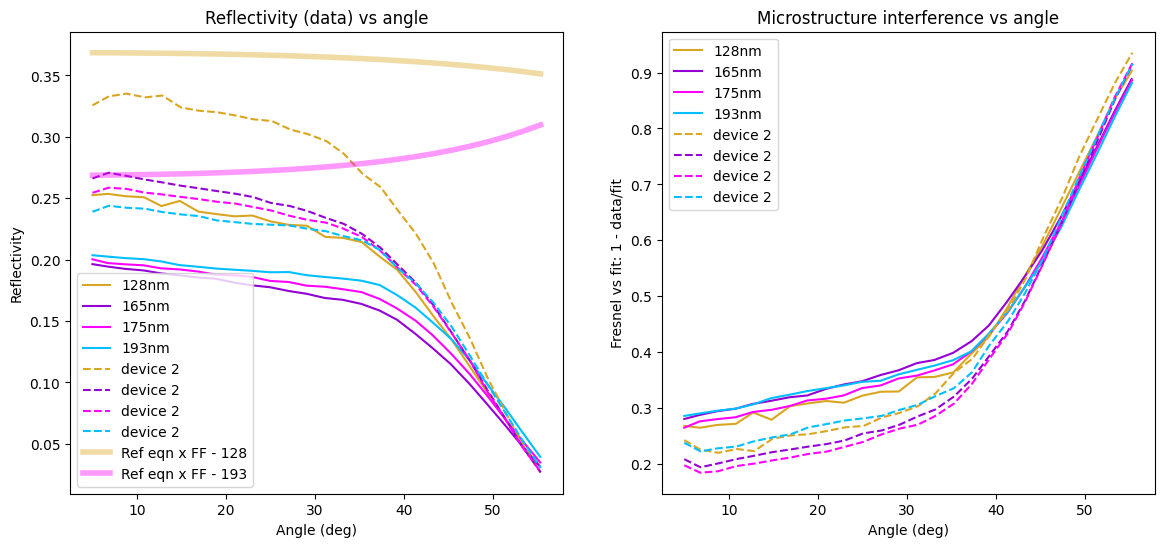

In [30]:
# plt.plot(xs, rs, label = "angle 1")
# plt.plot(xp, rp, label = "angle 2")
# plt.plot(xs, r, label = "average")

# device 1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 6))

xBlocked1Data = []
yBlocked1Data = []
ms.ResetColorCycle()
for data, wlen in zip(r1s, wlens):
    xAngle = data[0]
    r = data[1]
    r_equation = func_Ref(wlen = wlen, theta1=xAngle, toxide=dev1_thick, FF=FF1, scaleDown=0.0, gausSigma=None, dh=None)
    
    ax1.plot(xAngle, r, color = ms.GetNextColor(), label = f"{wlen}nm")
    ax2.plot(xAngle, 1-r/r_equation, color = ms.GetNextColor(1), label = f"{wlen}nm")
    yBlock = 1-r/r_equation
    yBlocked1Data.append(yBlock)
    xBlocked1Data.append(xAngle)

xBlocked2Data = []
yBlocked2Data = []
ms.ResetColorCycle()
for data, wlen in zip(r2s, wlens):
    xAngle = data[0]
    r = data[1]
    r_equation = func_Ref(wlen = wlen, theta1=xAngle, toxide=dev2_thick, FF=FF2, scaleDown=0.0, gausSigma=None, dh=None)
    
    ax1.plot(xAngle, r, color=ms.ResetColorCycle(), linestyle = "--", label = f"device 2")
    ax2.plot(xAngle, 1-r/r_equation, color=ms.ResetColorCycle(1), linestyle = "--", label = f"device 2")
    yBlock = 1-r/r_equation
    yBlocked2Data.append(yBlock)
    xBlocked2Data.append(xAngle)

xShow = r2s[0][0]
yShow = func_Ref(wlen = wlens[0], theta1=xShow, toxide=dev2_thick, FF=FF1, scaleDown=0.0, gausSigma=None, dh=None)
ax1.plot(xShow, yShow, color=ms.air.col,label = f"Ref eqn x FF - {wlens[0]}", linestyle="-", linewidth=4, alpha = 0.4)

yShow = func_Ref(wlen = wlens[3], theta1=xShow, toxide=dev2_thick, FF=FF1, scaleDown=0.0, gausSigma=None, dh=None)
ax1.plot(xShow, yShow, color=ms.lxe2.col,label = f"Ref eqn x FF - {wlens[3]}", linestyle="-", linewidth=4, alpha = 0.4)


ax1.set_xlabel("Angle (deg)")
ax2.set_xlabel("Angle (deg)")
ax1.set_ylabel("Reflectivity")
ax1.set_title("Reflectivity (data) vs angle")

ax2.set_ylabel("Fresnel vs fit: 1 - data/fit")
ax2.set_title("Microstructure interference vs angle")

ax1.legend()
ax2.legend()
plt.show()
# plt.plot(xs, func_Ref(wlen = wlens[0], theta1=xs, toxide=dev1_thick, FF=0.6, scaleDown=0.0, gausSigma=None, dh=None), label = "eqn A")

---
### Analyzing microstructure effect?

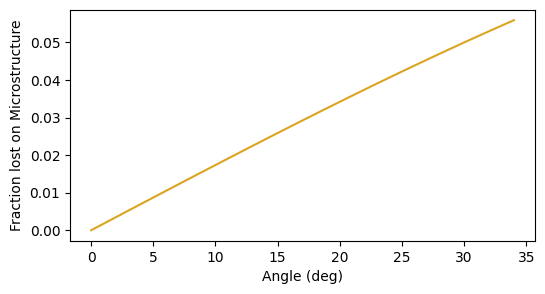

In [31]:
def fracLost_onStructure(theta, FF, FFh = 0.01):
    deg2rad = np.pi/180
    thetap = theta*deg2rad
    # p incidence (no theta)

    amountLostFromBeam = (1-FF) + FFh*np.sin(thetap)
    # beamOnFlat = Ascale/np.cos(thetap) # no cos(theta) scaling on bottom because we just hit more pixels with same structure
    
    return amountLostFromBeam

def effective_lost(theta, ffh, scaleDown):
    deg2rad = np.pi/180
    return 2*ffh * np.sin(theta*deg2rad) + scaleDown

xAngTest = np.arange(0, 35, 1)

area= 100
wEffective = (1-FF1)*np.sqrt(area)/4

plt.figure(figsize = (6, 3))
plt.plot(xAngTest, fracLost_onStructure(FF=FF1, FFh = 0.1, theta=xAngTest) - (1-FF1))
# plt.plot(xAngTest, np.sin(xAngTest*np.pi/180), label = "sin(theta)")

plt.xlabel("Angle (deg)")
plt.ylabel("Fraction lost on Microstructure")
plt.show()

effective vertical fill factor: 0.104 +/- 4.6E-06, 0.100+/- 3.2E-05


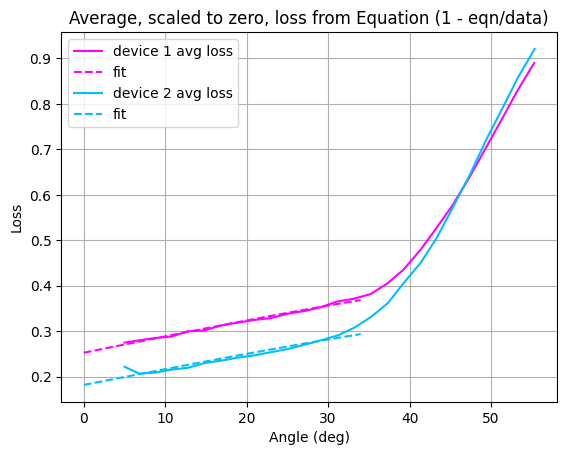

In [32]:
## Average loss vs angle
np.mean(yBlocked1Data, axis=1)

xBlocked1 = np.mean(xBlocked1Data, axis=0)
yBlocked1 = np.mean(yBlocked1Data, axis=0)

xBlocked2 = np.mean(xBlocked2Data, axis=0)
yBlocked2 = np.mean(yBlocked2Data, axis=0)

mask1 = xBlocked1 < 35
popt1, pcov1 = opt.curve_fit(effective_lost, xBlocked1[mask1], yBlocked1[mask1], p0=[0.01, yBlocked1[0]])

mask2 = xBlocked2 < 35
popt2, pcov2 = opt.curve_fit(effective_lost, xBlocked2[mask2], yBlocked2[mask2], p0=[0.01, yBlocked2[0]])

print(f"effective vertical fill factor: {popt1[0]:0.3f} +/- {pcov1[1, 1]:0.1E}, {popt2[0]:0.3f}+/- {pcov2[1, 1]:0.1E}")
# print(popt1, popt2)


xfitShow = np.arange(0, 35, 1)

plt.plot(xBlocked1, yBlocked1, color = ms.GetNextColor(), label = "device 1 avg loss")
plt.plot(xfitShow, effective_lost(xfitShow, *popt1), color = ms.GetNextColor(1), linestyle = "--", label = "fit")

plt.plot(xBlocked2, yBlocked2, color = ms.GetNextColor(), label = "device 2 avg loss")
plt.plot(xfitShow, effective_lost(xfitShow, *popt2), color = ms.GetNextColor(1), linestyle = "--", label = "fit")

plt.legend()
plt.title("Average, scaled to zero, loss from Equation (1 - eqn/data)")
plt.ylabel("Loss")
plt.xlabel("Angle (deg)")
plt.grid()

plt.show()